# KPCA Benchmarking

<i>

<h3> The point: </h3>

<i> You can get a feel for yourself whether to use `KPCA`/`PCA` by looking at these benchmarks. Feel free to browse! I made a lot more experiments than these, but here are the highlights!


<br>
<br>
<br>
<br>


<div style="border: 3px dashed white; padding: 10px; box-sizing: border-box;">

<h3> When could KPCA perform better than PCA?</h3>

<i>


* When the important relationships between features are **DEEPLY** non-linear in structure. (See Experiments 2-4)

* When the lines double back in the x, y plane (or multidimensionally) to create geometric shapes or nested shapes (dna, object detection, hyperspatial data). For normal PCA, this means the relationship within the large shape isn't captured. (See Experiment 5)

* When the nonlinear features are, in general, more useful than the linear features for predictions.

* When using linear regression models such as `Ridge` or `LinearRegressor`. This is because KPCA re-linearized the structure. (See experiment 2-3)

* When using non-parametric models (not confirmed)


</div>


<br>
<br>
<br>

### Experiment 1 UCI Electricity Usage, `LinearRegressor`:

This is the results all in one place, because not everyone has time.

|Data visual|Results|
|---|---|
|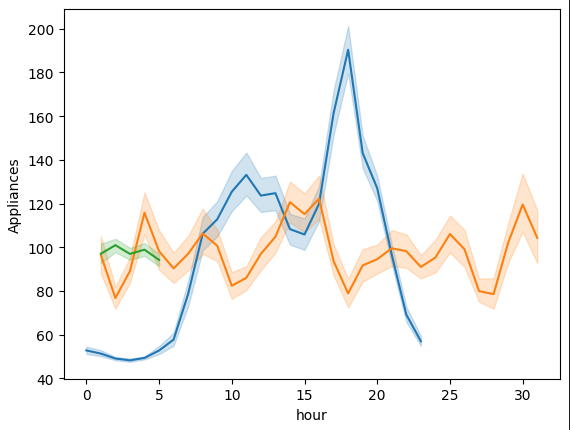|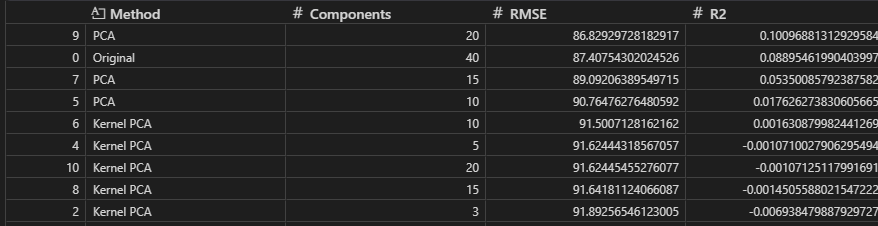|

### Experiment 2 SKLEARN housing data, `RandomForestRegressor`:

|Data visual|Results|
|---|---|
|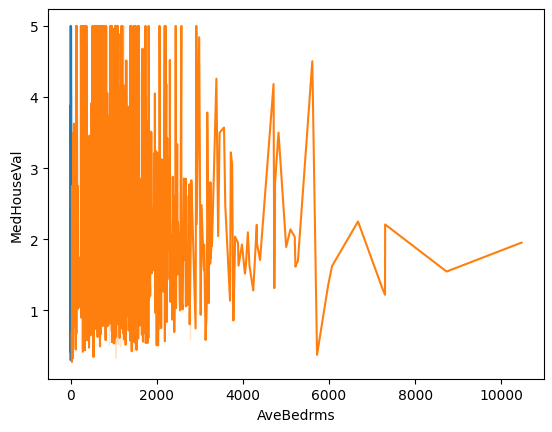|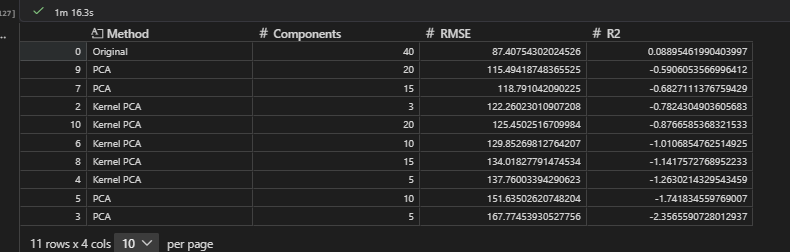|

### Experiment 3 SKLEARN housing data, `LinearRegressor`:

|Data visual|Results|
|---|---|
|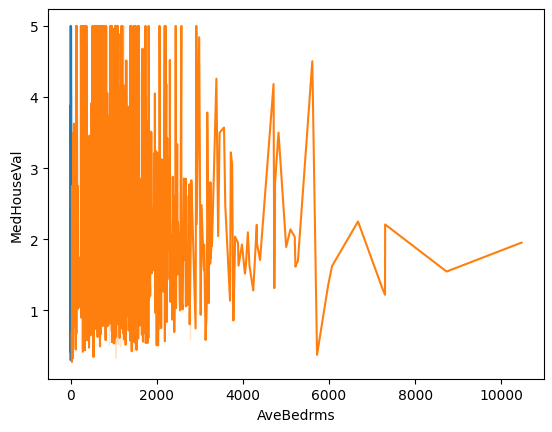|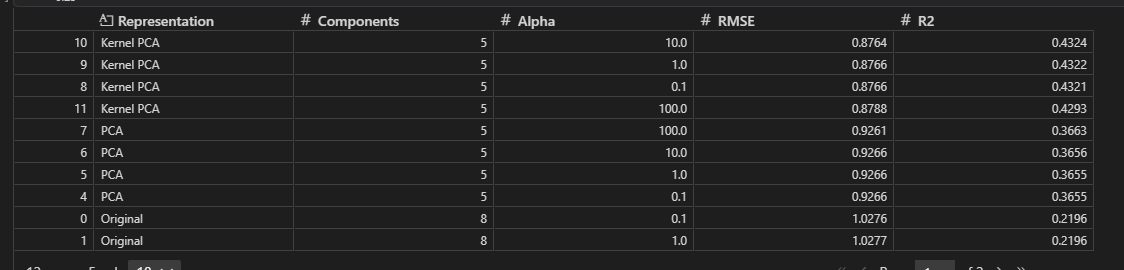|


### Experiment 4 SKLEARN housing data, `Ridge`:

|Data visual|Results|
|---|---|
|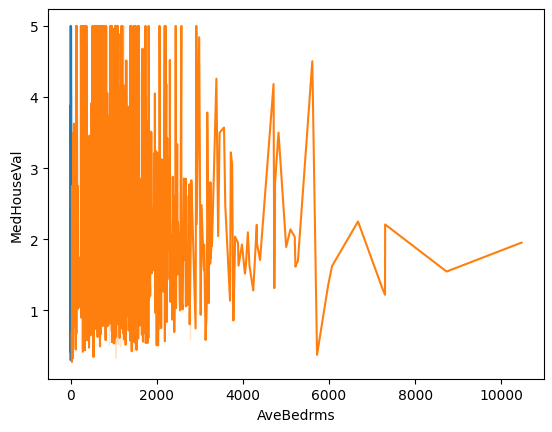|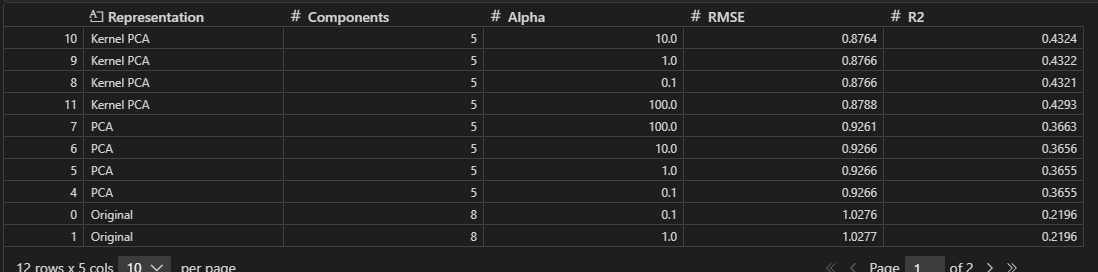
|

### Experiment 5: Nested, Concentric-circles, `LogisticRegressor`:

|Data visual|Results|
|---|---|
|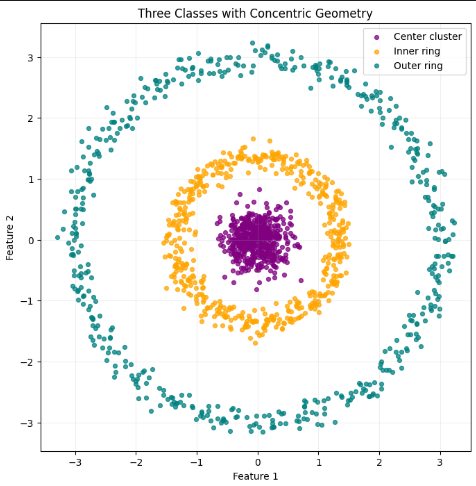|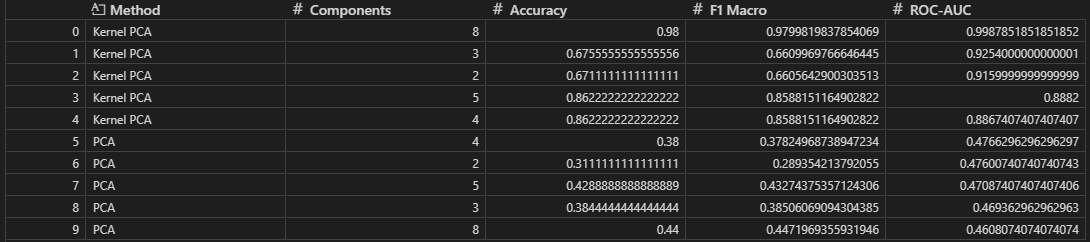|



<i> <strong style='color:orange ; background-color:black;'>




</strong>

---



Dataset: https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

<br>
<br>


# Experiment dataset 1


#### Let's try a basic energy consumption seasonality dataset:

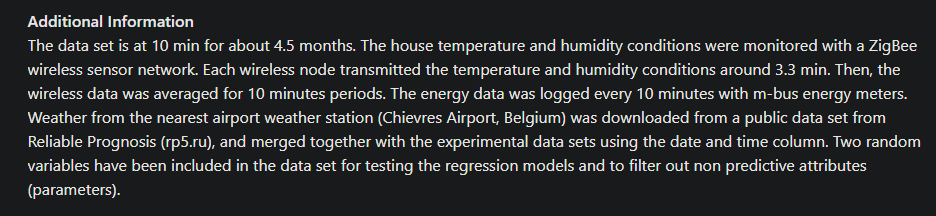 

Here, we're going to predict the Wh of our appliances for the given home.


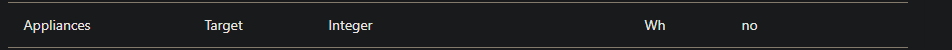


<i> This dataset has:

* Non-linear relationships

* A lot of features



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("energydata_complete.csv")

# # Now we convert the date to datetime, so we can
# # Extract the months, years, weeks.
df["date"] = pd.to_datetime(df["date"])

# Extract calendar features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["week"] = df["date"].dt.isocalendar().week
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek

# Extract time features
df["hour"] = df["date"].dt.hour
df["minute"] = df["date"].dt.minute
df["second"] = df["date"].dt.second

# Additional useful features
df["quarter"] = df["date"].dt.quarter
df["day_of_year"] = df["date"].dt.dayofyear
df["is_weekend"] = (df["date"].dt.dayofweek >= 5).astype(int)

# Cyclical encoding (Weekdays go into circles, who woulda thought?) 
df["day_of_week_sin"] = np.sin(2 * np.pi * df["day_of_week"] / 7)
df["day_of_week_cos"] = np.cos(2 * np.pi * df["day_of_week"] / 7)

# Dropping unnecesary columns. 
df = df.drop(["date"], axis=1)

# There are no missing values.

df

# Notice there are a ton of columns as well. Potentially enough to cause in a simple ML model. 

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,day,day_of_week,hour,minute,second,quarter,day_of_year,is_weekend,day_of_week_sin,day_of_week_cos
0,60,30,19.890000,47.596667,19.200000,44.790000,19.790000,44.730000,19.000000,45.566667,...,11,0,17,0,0,1,11,0,0.000000,1.000000
1,60,30,19.890000,46.693333,19.200000,44.722500,19.790000,44.790000,19.000000,45.992500,...,11,0,17,10,0,1,11,0,0.000000,1.000000
2,50,30,19.890000,46.300000,19.200000,44.626667,19.790000,44.933333,18.926667,45.890000,...,11,0,17,20,0,1,11,0,0.000000,1.000000
3,50,40,19.890000,46.066667,19.200000,44.590000,19.790000,45.000000,18.890000,45.723333,...,11,0,17,30,0,1,11,0,0.000000,1.000000
4,60,40,19.890000,46.333333,19.200000,44.530000,19.790000,45.000000,18.890000,45.530000,...,11,0,17,40,0,1,11,0,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19730,100,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.700000,45.590000,...,27,4,17,20,0,2,148,0,-0.433884,-0.900969
19731,90,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.700000,45.590000,...,27,4,17,30,0,2,148,0,-0.433884,-0.900969
19732,270,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.700000,45.730000,...,27,4,17,40,0,2,148,0,-0.433884,-0.900969
19733,420,10,25.500000,46.990000,25.414000,43.036000,26.890000,41.290000,24.700000,45.790000,...,27,4,17,50,0,2,148,0,-0.433884,-0.900969


### The problem

<i> Behold, non-linearity.

And also, a lot of columns. 

Will `PCA`, `KPCA`, or the original work best?

<Axes: xlabel='hour', ylabel='Appliances'>

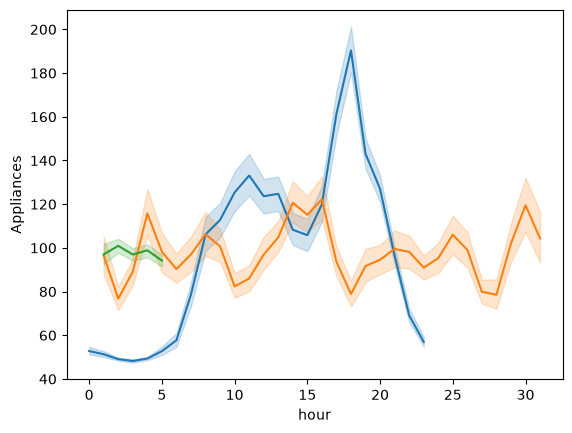

In [2]:
# Here, we have some seasonality. Classic non-linearity.
sns.lineplot(df, x="hour", y="Appliances")
sns.lineplot(df, x="day", y="Appliances")
sns.lineplot(df, x="month", y="Appliances")

# Applicances are used the most at around 1900 hours. 

### Temporal, and X y split

In [3]:

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.linear_model import LinearRegression

# X, y split.
y = df["Appliances"]
X = df.drop("Appliances", axis=1)

# Temporal Split
split_idx = int(len(X) * 0.7)
X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]


### LinearRegressor

<i> Let's first start with a basic, linear model and benchmark that.

In [4]:


# Scale first.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# We're going to add all our resutls in here.
results = []

# Baseline using all original features
model = LinearRegression()
model.fit(X_train_scaled, y_train)
preds = model.predict(X_test_scaled)

results.append({
    "Method": "Original",
    "Components": X_train.shape[1],
    "RMSE": root_mean_squared_error(y_test, preds),
    "R2": r2_score(y_test, preds)
})

# This is the number of Principle Components we're
# going to loop by.
for n in [3, 5, 10, 15, 20]:

    # Here, we're looping by PCA and KPCA and appending
    # results. 
    for name, reducer in [
        ("PCA", PCA(n_components=n)),  
        ("Kernel PCA", KernelPCA(      
            n_components=n,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        ))]:

        # Initialize, fit and predict!
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)
        model = LinearRegression()
        model.fit(Xtr, y_train)
        preds = model.predict(Xte)

        # Append results and add the metrics.
        results.append({
            "Method": name,
            "Components": n,
            "RMSE": root_mean_squared_error(y_test, preds),
            "R2": r2_score(y_test, preds)
        })

# Put the results into a dataframe.
results_df = pd.DataFrame(results)

results_df


,Method,Components,RMSE,R2
0,Original,40,87.407543,0.088955
1,PCA,3,94.364422,-0.061839
2,Kernel PCA,3,91.892565,-0.006938
3,PCA,5,92.181691,-0.013285
4,Kernel PCA,5,91.624443,-0.001071
5,PCA,10,90.764763,0.017626
6,Kernel PCA,10,91.500713,0.001631
7,PCA,15,89.092064,0.053501
8,Kernel PCA,15,91.641811,-0.001451
9,PCA,20,86.829297,0.100969


### RandomForestRegressor

<i>

Now, let's use randomforest.

In [5]:


# Scale first.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# We're going to add all our resutls in here.
results = []

# Baseline using all original features
model = LinearRegression()
model.fit(X_train_scaled, y_train)
preds = model.predict(X_test_scaled)

results.append({
    "Method": "Original",
    "Components": X_train.shape[1],
    "RMSE": root_mean_squared_error(y_test, preds),
    "R2": r2_score(y_test, preds)
})

# This is the number of Principle Components we're
# going to loop by.
for n in [3, 5, 10, 15, 20]:

    # Here, we're looping by PCA and KPCA and appending
    # results. 
    for name, reducer in [
        ("PCA", PCA(n_components=n)),  
        ("Kernel PCA", KernelPCA(      
            n_components=n,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        ))]:

        # Initialize, fit and predict!
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)
        model = RandomForestRegressor(
            n_estimators=200,
            random_state=101,
            n_jobs=-1
        )
        model.fit(Xtr, y_train)
        preds = model.predict(Xte)

        # Append results and add the metrics.
        results.append({
            "Method": name,
            "Components": n,
            "RMSE": root_mean_squared_error(y_test, preds),
            "R2": r2_score(y_test, preds)
        })

# Put the results into a dataframe.
results_df = pd.DataFrame(results)

results_df.sort_values("R2", ascending=False)

,Method,Components,RMSE,R2
0,Original,40,87.407543,0.088955
9,PCA,20,115.494187,-0.590605
7,PCA,15,118.791042,-0.682711
2,Kernel PCA,3,122.119220,-0.778321
10,Kernel PCA,20,125.157110,-0.867898
6,Kernel PCA,10,130.605239,-1.034058
8,Kernel PCA,15,134.001568,-1.141223
4,Kernel PCA,5,137.158109,-1.243289
5,PCA,10,151.650941,-1.742410
3,PCA,5,167.774539,-2.356559


---

# Experiment Dataset 2

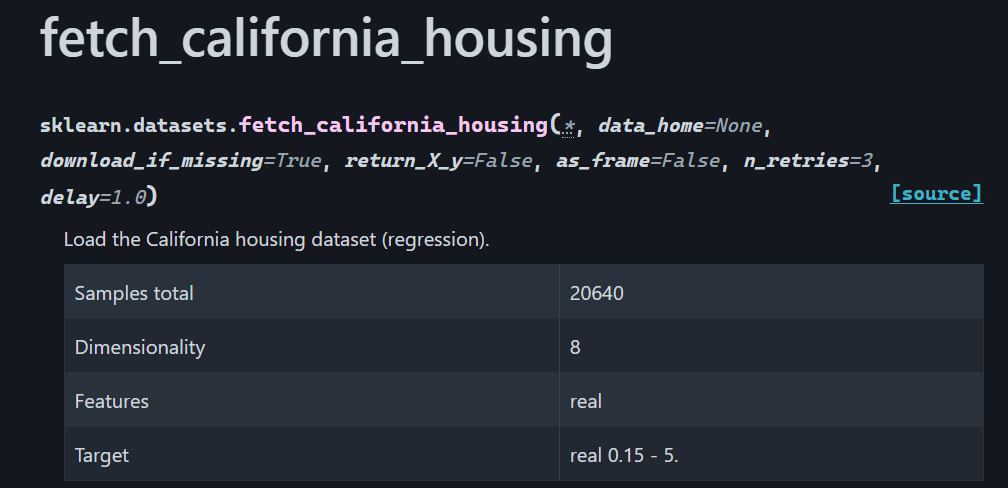


<i> The classic california housing dataset. Quite noisy and it comes scaled. We'll likely run it through a standardscaler anyways just in case it's not standardized.

In [6]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Grabbing housing dataset from sklearn. 
housing = fetch_california_housing()

# Loading dataframe
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Target housing. For some reason it's separate from the dataset.
df["MedHouseVal"] = housing.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<Axes: xlabel='Population', ylabel='MedHouseVal'>

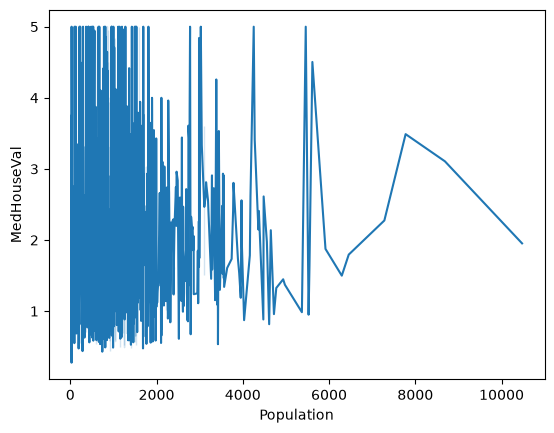

In [7]:
# How about giving it noisy, deeply non-linear data?
sns.lineplot(df.sample(1000), x="Population", y="MedHouseVal")

In [8]:

# X, y split.
y = df["MedHouseVal"]
X = df.drop("MedHouseVal", axis=1)

# Data split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101
)

# Standard scaling, which is really what we want right now for the dataset.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# We're going to add all our results in here.
results = []

# Baseline using all original features
model = RandomForestRegressor(
    n_estimators=200,
    random_state=101,
    n_jobs=-1
)


model.fit(X_train_scaled, y_train)
preds = model.predict(X_test_scaled)

# Your classic regression metrics
results.append({
    "Method": "Original",
    "Components": X_train.shape[1],
    "RMSE": root_mean_squared_error(y_test, preds),
    "R2": r2_score(y_test, preds)
})


# Store the full KPCA training representation for analysis.
kpca_analysis = KernelPCA(
    n_components=8,
    kernel="rbf",
    gamma=0.1,
    eigen_solver="arpack"
)
Xtr_kpca = kpca_analysis.fit_transform(X_train_scaled)

# We use item comrehension to make a fancy column name here
# when putting it into a dataframe.
components_df = pd.DataFrame(
    Xtr_kpca,
    columns=[f"KPCA_{i+1}" for i in range(8)],
    index=y_train.index
)

components_df["MedHouseVal"] = y_train


# This is the number of Principal Components we're
# going to loop by.
for n in [3, 4, 5, 6, 8]:

    # Loop by PCA and KPCA and append results.
    for name, reducer in [
        ("PCA", PCA(n_components=n)),
        ("Kernel PCA", KernelPCA(
            n_components=n,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        ))
    ]:

        # Initialize, fit and predict!
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)

        model = LinearRegression()
        model.fit(Xtr, y_train)
        preds = model.predict(Xte)

        # Append results and add the metrics.
        results.append({
            "Method": name,
            "Components": n,
            "RMSE": root_mean_squared_error(y_test, preds),
            "R2": r2_score(y_test, preds)
        })

# Put the results into a dataframe.
results_df = pd.DataFrame(results)

results_df.sort_values("R2", ascending=False)

,Method,Components,RMSE,R2
0,Original,8,0.528059,0.793941
10,Kernel PCA,8,0.851134,0.464669
6,Kernel PCA,5,0.876612,0.432140
8,Kernel PCA,6,0.876696,0.432031
4,Kernel PCA,4,0.883560,0.423103
2,Kernel PCA,3,0.889685,0.415077
5,PCA,5,0.926630,0.365490
9,PCA,8,1.027620,0.219645
1,PCA,3,1.145066,0.031081
7,PCA,6,1.203824,-0.070908


In [9]:

# X, y split.
y = df["MedHouseVal"]
X = df.drop("MedHouseVal", axis=1)

# Data split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101
)

# Scale first.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# We're going to add all our results in here.
results = []

# Baseline using all original features
model = LinearRegression()
model.fit(X_train_scaled, y_train)
preds = model.predict(X_test_scaled)

results.append({
    "Method": "Original",
    "Components": X_train.shape[1],
    "RMSE": root_mean_squared_error(y_test, preds),
    "R2": r2_score(y_test, preds)
})


# Store the full KPCA training representation for analysis.
kpca_analysis = KernelPCA(
    n_components=8,
    kernel="rbf",
    gamma=0.1,
    eigen_solver="arpack"
)

Xtr_kpca = kpca_analysis.fit_transform(X_train_scaled)

components_df = pd.DataFrame(
    Xtr_kpca,
    columns=[f"KPCA_{i+1}" for i in range(8)],
    index=y_train.index
)

components_df["MedHouseVal"] = y_train


# This is the number of Principal Components we're
# going to loop by.
for n in [3, 4, 5, 6, 8]:

    # Loop by PCA and KPCA and append results.
    for name, reducer in [
        ("PCA", PCA(n_components=n)),
        ("Kernel PCA", KernelPCA(
            n_components=n,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        ))
    ]:

        # Initialize, fit and predict!
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)

        model = LinearRegression()
        model.fit(Xtr, y_train)
        preds = model.predict(Xte)

        # Append results and add the metrics.
        results.append({
            "Method": name,
            "Components": n,
            "RMSE": root_mean_squared_error(y_test, preds),
            "R2": r2_score(y_test, preds)
        })

# Put the results into a dataframe.
results_df = pd.DataFrame(results)

results_df.sort_values("R2", ascending=False)


,Method,Components,RMSE,R2
10,Kernel PCA,8,0.851134,0.464669
6,Kernel PCA,5,0.876612,0.432140
8,Kernel PCA,6,0.876696,0.432031
4,Kernel PCA,4,0.883560,0.423103
2,Kernel PCA,3,0.889685,0.415077
5,PCA,5,0.926630,0.365490
0,Original,8,1.027620,0.219645
9,PCA,8,1.027620,0.219645
1,PCA,3,1.145066,0.031081
7,PCA,6,1.203824,-0.070908


### RidgeRegressor

In [10]:

import pandas as pd

from sklearn.decomposition import PCA, KernelPCA
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error, r2_score

results = []

# Try the original features, PCA, and Kernel PCA.
representations = [
    ("Original", None),
    ("PCA", PCA(n_components=5)),
    (
        "Kernel PCA",
        KernelPCA(
            n_components=5,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        )
    )
]

# Try different regularization strengths. We could be more comprehensive here
# And try 130, 150. But this already is a long notebook.
alphas = [0.1, 1.0, 10.0, 100.0]


# For each reducer...
for representation_name, reducer in representations:

    # Scale it if needed.
    if reducer is None:
        Xtr = X_train_scaled
        Xte = X_test_scaled
    else:
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)

    # Fit the model using alpha and append the results.
    for alpha in alphas:
        model = Ridge(alpha=alpha)
        model.fit(Xtr, y_train)

        predictions = model.predict(Xte)

        # Append it, otherwise set component to the number of components
        # above. Otherwise it will crash and fail.
        results.append({
            "Representation": representation_name,
            "Components": (
                X_train_scaled.shape[1] if reducer is None else 5
            ),
            "Alpha": alpha,
            "RMSE": root_mean_squared_error(y_test, predictions),
            "R2": r2_score(y_test, predictions)
        })

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE").round(4)


,Representation,Components,Alpha,RMSE,R2
10,Kernel PCA,5,10.0,0.8764,0.4324
9,Kernel PCA,5,1.0,0.8766,0.4322
8,Kernel PCA,5,0.1,0.8766,0.4321
11,Kernel PCA,5,100.0,0.8788,0.4293
7,PCA,5,100.0,0.9261,0.3663
6,PCA,5,10.0,0.9266,0.3656
5,PCA,5,1.0,0.9266,0.3655
4,PCA,5,0.1,0.9266,0.3655
0,Original,8,0.1,1.0276,0.2196
1,Original,8,1.0,1.0277,0.2196


# Experiment Dataset 3

### Circles within circles! (nonconcentric circles).

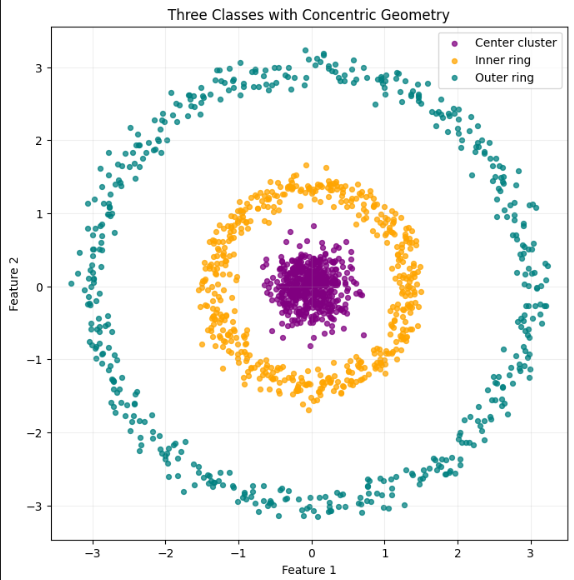

<i> In this case, I used AI to make me some non-concentric shapes, in this case circles. (chatgpt 5). 

KPCA is very good at interpreting these shapes, as the 'kernel trick' unravels the inner circles into a separate, linear space. I'm expecting very good results for `KPCA`

We're going to be using classification here, as that makes interpretation for results a bit easier when visualizing it as well.

In [11]:
import numpy as np
import pandas as pd

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


# 1. Create the nested-circles dataset

# Generate two concentric circles.
X_rings, y_rings = make_circles(
    n_samples=1000,
    factor=0.45,
    noise=0.04,
    random_state=101
)

# Enlarge the rings.
X_rings = X_rings * 3

# Label the outer ring 2 and inner ring 1.
y_rings = np.where(y_rings == 0, 2, 1)

# Create a third class in the center.
rng = np.random.default_rng(101)
X_center = rng.normal(loc=0, scale=0.25, size=(500, 2))
y_center = np.zeros(500, dtype=int)

# Combine the three classes.
X_2d = np.vstack([X_rings, X_center])
y = np.concatenate([y_rings, y_center])


# 2. Expand the dataset to 35 features


# Keep the original two coordinates.
features = [X_2d[:, 0], X_2d[:, 1]]

# Add nonlinear transformations of the coordinates.
weights = rng.normal(size=(2, 33))

for i in range(33):
    transformed = np.sin(X_2d @ weights[:, i])
    features.append(transformed)

# Convert to a DataFrame.
X = pd.DataFrame(
    np.column_stack(features),
    columns=[f"feature_{i}" for i in range(1, 36)]
)

df = X.copy()
df["target"] = y

print(df.shape)  # 1500 rows, 36 columns including target


# 3. X, y split


y = df["target"]
X = df.drop("target", axis=1)

# Data split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=101,
    stratify=y
)

# Scale first.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 4. Store results

results = []

# Baseline using all original features.
model = LogisticRegression(max_iter=2000)
model.fit(X_train_scaled, y_train)

preds = model.predict(X_test_scaled)
probs = model.predict_proba(X_test_scaled)

results.append({
    "Method": "Original",
    "Components": X_train.shape[1],
    "Accuracy": accuracy_score(y_test, preds),
    "F1 Macro": f1_score(y_test, preds, average="macro"),
    "ROC-AUC": roc_auc_score(
        y_test, probs, multi_class="ovr", average="macro"
    )
})

# 5. Compare PCA and Kernel PCA

for n in [2, 3, 4, 5, 8]:

    for name, reducer in [
        ("PCA", PCA(n_components=n)),
        ("Kernel PCA", KernelPCA(
            n_components=n,
            kernel="rbf",
            gamma=0.1,
            eigen_solver="arpack"
        ))
    ]:

        # Fit dimensionality reduction on training data.
        Xtr = reducer.fit_transform(X_train_scaled)
        Xte = reducer.transform(X_test_scaled)

        # Train the same model on the reduced features.
        model = LogisticRegression(max_iter=2000)
        model.fit(Xtr, y_train)

        preds = model.predict(Xte)
        probs = model.predict_proba(Xte)

        # Append results.
        results.append({
            "Method": name,
            "Components": n,
            "Accuracy": accuracy_score(y_test, preds),
            "F1 Macro": f1_score(y_test, preds, average="macro"),
            "ROC-AUC": roc_auc_score(y_test, probs, multi_class="ovr", average="macro")
        })


# 6. Display results

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="ROC-AUC",ascending=False).reset_index(drop=True)
results_df


(1500, 36)


,Method,Components,Accuracy,F1 Macro,ROC-AUC
0,Kernel PCA,8,0.980000,0.979982,0.998785
1,Kernel PCA,3,0.675556,0.660997,0.925400
2,Kernel PCA,2,0.671111,0.660564,0.916000
3,Kernel PCA,5,0.862222,0.858815,0.888200
4,Kernel PCA,4,0.862222,0.858815,0.886741
5,PCA,4,0.380000,0.378250,0.476630
6,PCA,2,0.311111,0.289354,0.476007
7,PCA,5,0.428889,0.432744,0.470874
8,PCA,3,0.384444,0.385061,0.469363
9,PCA,8,0.440000,0.447197,0.460807


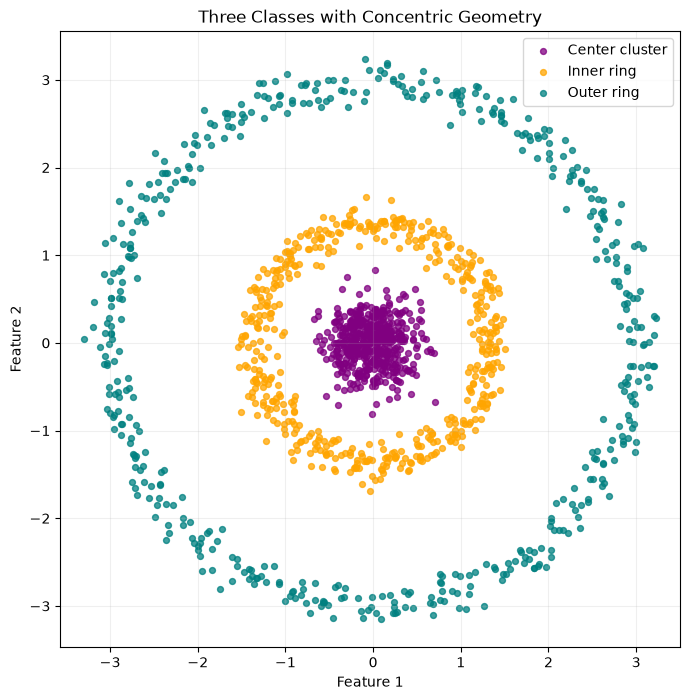

In [12]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
import numpy as np

# Generate two concentric circles
X_rings, y_rings = make_circles(
    n_samples=1000,
    factor=0.45,
    noise=0.04,
    random_state=101
)

# Enlarge both rings
X_rings = X_rings * 3

# Create a third class in the center
rng = np.random.default_rng(101)

X_center = rng.normal(
    loc=0,
    scale=0.25,
    size=(500, 2)
)

y_center = np.zeros(500, dtype=int)

# Combine the rings and center
X = np.vstack([X_rings, X_center])
y = np.concatenate([
    np.where(y_rings == 0, 2, 1),
    y_center
])

# Plot the dataset
plt.figure(figsize=(8, 8))

colors = {
    0: "purple",
    1: "orange",
    2: "teal"
}

labels = {
    0: "Center cluster",
    1: "Inner ring",
    2: "Outer ring"
}

for class_id in [0, 1, 2]:
    mask = y == class_id

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        c=colors[class_id],
        label=labels[class_id],
        s=18,
        alpha=0.75
    )

plt.title("Three Classes with Concentric Geometry")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.axis("equal")
plt.legend()
plt.grid(alpha=0.2)
plt.show()